# Does Batch Normalisation Make Training Less Fragile?

*Exploration of learning-rate sensitivity and training stability on Fashion-MNIST.*

---

## Introduction: The Hyperparameter Tightrope

Training a deep network can feel like walking a tightrope. On one side lies the canyon of **underfitting** (steps too small, training too slow); on the other, the abyss of **divergence** (steps too large, training collapses). The **learning rate (LR)** decides which side you fall on, and finding a good value is often trial and error.

But what if there were a safety net? **Batch Normalisation (BN)** is widely credited with stabilising training. Does it actually widen your margin for error? If you pick a sub-optimal learning rate, can BN save the run?

To find out, I ran a controlled experiment: a small CNN on **Fashion-MNIST**, five learning rates, with and without BN, three random seeds each. In short: BN made no difference at a well-chosen learning rate, but it moved the point where training breaks down up by roughly a factor of ten. It did not make training immune. Everything can be reproduced by running this notebook top to bottom.

---

## 1. Background: learning rate and batch norm

**The learning rate.** Training adjusts the weights $\theta$ to reduce a loss $\mathcal{L}$ with the rule

$$\theta \leftarrow \theta - \eta \, \nabla_\theta \mathcal{L}(\theta)$$

The gradient gives the direction; the learning rate $\eta$ gives the step size. Too small and training is slow; too large and the steps overshoot, the loss blows up and the network can stall at chance accuracy. It is usually the most sensitive hyperparameter, and good values span orders of magnitude, so learning rates are searched on a **log scale**.

**Batch normalisation.** In a deep network the activations can drift to very large or very small scales, which makes gradients erratic. BN keeps them in a steady range: for each channel it standardises the activations with the mini-batch mean $\mu_B$ and variance $\sigma_B^2$, then rescales them with two learned parameters $\gamma$ and $\beta$:

$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma \hat{x} + \beta$$

Here it sits after each convolution (Conv → BN → ReLU → MaxPool) and adds only 192 parameters. At test time it uses running averages collected during training.

**Why it should help.** BN's creators (Ioffe & Szegedy, 2015) argued it reduces *internal covariate shift*, the constant change in each layer's input distribution. Later work ([Santurkar et al., 2018](https://arxiv.org/abs/1805.11604)) found this is not the main reason and argued instead that BN **smooths the optimisation landscape**: the loss and its gradients change more gradually, so a step in the gradient direction is more predictable. Picture a rugged terrain of ravines and cliffs, where a slightly-too-large step throws you off an edge; BN acts like a shock absorber. Both explanations predict the same thing, which is what I test: **with BN, a wider range of learning rates should work.** The experiment tests that prediction, not the mechanism.

---

## 2. Experiment setup

A fair fight: I change one thing at a time and fix everything else.

* **Model:** a small CNN with 2 convolutional blocks and 2 fully connected layers (421,642 parameters without BN, 421,834 with).
* **Task:** Fashion-MNIST, using a **10,000-image training subset** for speed, with 10% of the full training set (6,000 images) held out for validation.
* **Optimiser:** Adam, batch size 64, dropout 0.25, 5 epochs, no early stopping, no augmentation.
* **Variable:** learning rate $\eta \in \{10^{-4}, 10^{-3}, 10^{-2}, 3\cdot10^{-2}, 10^{-1}\}$, each with batch norm **on and off**.
* **Seeds:** 42, 43, 44 (the seed controls weight initialisation, the train/validation split and shuffling), so I can separate real differences from noise.

All comparisons use the **validation** set; the test set is never used. The code below is the class framework (`hyperparameters_lightning.ipynb`), unchanged. The experiment itself starts in section 3.

### Setup code

In [ ]:
%pip install torch torchvision lightning pandas matplotlib

In [ ]:
import logging
import random
import time
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Lightning 2.x is imported as `lightning`; older installs use `pytorch_lightning`.
try:
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    _LIGHTNING_LOGGER = "lightning.pytorch"
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
    from pytorch_lightning.loggers import CSVLogger
    _LIGHTNING_LOGGER = "pytorch_lightning"

# Keep the output readable during the many short training runs below.
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

print("torch:", torch.__version__)
print("lightning:", L.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.14.1+cu130
lightning: 2.6.6
GPU available: True


### Framework from the class notebook (unchanged)

In [ ]:
@dataclass
class HParams:
    # ---- Data -------------------------------------------------------------
    data_dir: str = "./data"
    batch_size: int = 64          # samples per gradient step
    val_fraction: float = 0.1     # share of the training set held out for validation
    train_subset: Optional[int] = None  # use only N training images (None = all); for fast experiments
    augment: bool = False         # random crop + horizontal flip on training images
    num_workers: int = 0          # data-loading processes (not a model hyperparameter; 0 is safest in notebooks)

    # ---- Model ------------------------------------------------------------
    conv1_channels: int = 32      # width of the first conv block
    conv2_channels: int = 64      # width of the second conv block
    hidden_dim: int = 128         # size of the fully connected layer
    activation: str = "relu"      # relu | leaky_relu | gelu | tanh
    use_batchnorm: bool = True    # batch normalisation after each conv
    dropout: float = 0.25         # probability of zeroing an activation in the classifier head

    # ---- Optimisation -----------------------------------------------------
    optimizer: str = "adam"       # sgd | adam | adamw
    lr: float = 1e-3              # learning rate (step size)
    momentum: float = 0.9         # used by SGD only
    weight_decay: float = 0.0     # L2-style penalty on the weights
    scheduler: str = "none"       # none | step | cosine

    # ---- Training loop ----------------------------------------------------
    max_epochs: int = 5           # upper limit on passes over the training set
    patience: int = 3             # early stopping: epochs without val_loss improvement before stopping
    seed: int = 42                # controls weight init, data split and shuffling


hp = HParams()
pd.Series(asdict(hp), name="value").to_frame()

,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,None
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


In [ ]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Mean and standard deviation of the Fashion-MNIST training pixels.
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])

        augmentations = []
        if hp.augment:  # <-- hyperparameter: augment
            augmentations = [transforms.RandomCrop(28, padding=2),
                             transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        # Download once. Lightning calls this on a single process.
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        # Two views of the same 60k images: one with training transforms, one without.
        train_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.eval_transform)

        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)  # <-- hyperparameter: val_fraction
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]

        if self.hp.train_subset is not None:  # <-- hyperparameter: train_subset
            train_idx = train_idx[: self.hp.train_subset]

        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.FashionMNIST(self.hp.data_dir, train=False, transform=self.eval_transform)

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                          num_workers=self.hp.num_workers,
                          persistent_workers=self.hp.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)  # <-- hyperparameter: batch_size

    def val_dataloader(self):
        # The evaluation batch size only affects speed, never the result.
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

In [ ]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU, "tanh": nn.Tanh}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]            # <-- hyperparameter: activation
        c1, c2 = hp.conv1_channels, hp.conv2_channels  # <-- hyperparameters: width

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:                    # <-- hyperparameter: use_batchnorm
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(conv_block(1, c1), conv_block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),                 # <-- hyperparameter: dropout
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),   # <-- hyperparameter: hidden_dim
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = SmallCNN(hp)
print(model)
print(f"\ntrainable parameters: {count_parameters(model):,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 421,834


In [ ]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))  # logged + stored in checkpoints
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        # on_epoch=True: Lightning averages over the epoch (weighted by batch size).
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        hp = self.hp
        params = self.parameters()

        # <-- hyperparameters: optimizer, lr, momentum, weight_decay
        if hp.optimizer == "sgd":
            optimizer = torch.optim.SGD(params, lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            optimizer = torch.optim.Adam(params, lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(params, lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"unknown optimizer: {hp.optimizer}")

        # <-- hyperparameter: scheduler
        if hp.scheduler == "none":
            return optimizer
        if hp.scheduler == "step":
            scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, hp.max_epochs // 3), gamma=0.1)
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp.max_epochs)
        else:
            raise ValueError(f"unknown scheduler: {hp.scheduler}")
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}

In [ ]:
def load_history(log_dir) -> pd.DataFrame:
    """Read Lightning's metrics.csv and return one row per epoch."""
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    cols = [c for c in ["train_loss", "val_loss", "train_acc", "val_acc"] if c in df.columns]
    return df.groupby("epoch")[cols].mean().reset_index()


def fit(hp: HParams, run_name: str = "run", verbose: bool = True, checkpoint: bool = False):
    """Train one model from a config. Returns (trainer, model, datamodule, history)."""
    for name in (_LIGHTNING_LOGGER, "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.INFO if verbose else logging.ERROR)
    L.seed_everything(hp.seed, workers=True)  # <-- hyperparameter: seed

    datamodule = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)

    callbacks = [EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)]  # <-- hyperparameter: patience
    if checkpoint:
        callbacks.append(ModelCheckpoint(monitor="val_acc", mode="max", save_top_k=1))

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,          # <-- hyperparameter: max_epochs
        accelerator="auto",                # GPU if there is one, otherwise CPU
        devices=1,
        logger=logger,
        callbacks=callbacks,
        enable_checkpointing=checkpoint,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
        log_every_n_steps=10,
    )
    trainer.fit(model, datamodule=datamodule)
    history = load_history(logger.log_dir)
    return trainer, model, datamodule, history

---

## 3. Running the experiment

The configuration below is the whole experiment: 2 batch-norm settings × 5 learning rates × 3 seeds = 30 short runs.

In [ ]:
BASE = replace(HParams(), optimizer="adam", batch_size=64, dropout=0.25,
               train_subset=10_000, max_epochs=5, patience=100, augment=False)

LRS   = [1e-4, 1e-3, 1e-2, 3e-2, 1e-1]
BN    = [True, False]
SEEDS = [42, 43, 44]

setup = pd.Series({k: getattr(BASE, k) for k in
    ["optimizer","batch_size","dropout","train_subset","max_epochs","val_fraction","augment"]})
setup["seeds"] = SEEDS
setup["lr values"] = LRS
setup["trainable params (BN on)"]  = count_parameters(SmallCNN(replace(BASE, use_batchnorm=True)))
setup["trainable params (BN off)"] = count_parameters(SmallCNN(replace(BASE, use_batchnorm=False)))
setup.to_frame("value")

,value
optimizer,adam
batch_size,64
dropout,0.25
train_subset,10000
max_epochs,5
val_fraction,0.1
augment,False
seeds,"[42, 43, 44]"
lr values,"[0.0001, 0.001, 0.01, 0.03, 0.1]"
trainable params (BN on),421834


In [ ]:
runs = {}   # (use_bn, lr, seed) -> history
for bn in BN:
    for lr in LRS:
        for seed in SEEDS:
            hp_i = replace(BASE, use_batchnorm=bn, lr=lr, seed=seed)
            _, _, _, h = fit(hp_i, run_name=f"bn_{bn}/lr_{lr:g}/seed_{seed}", verbose=False)
            runs[(bn, lr, seed)] = h
            print(f"BN={bn!s:<5} lr={lr:<7g} seed={seed}  best val_acc={h['val_acc'].max():.4f}")

BN=True  lr=0.0001  seed=42  best val_acc=0.8677


BN=True  lr=0.0001  seed=43  best val_acc=0.8737


BN=True  lr=0.0001  seed=44  best val_acc=0.8700


BN=True  lr=0.001   seed=42  best val_acc=0.8772


BN=True  lr=0.001   seed=43  best val_acc=0.8753


BN=True  lr=0.001   seed=44  best val_acc=0.8817


... (20 outputs left out)

BN=False lr=0.03    seed=44  best val_acc=0.7702


BN=False lr=0.1     seed=42  best val_acc=0.1078


BN=False lr=0.1     seed=43  best val_acc=0.1000


BN=False lr=0.1     seed=44  best val_acc=0.1062


---

## 4. Results

### Figure 1: learning curves

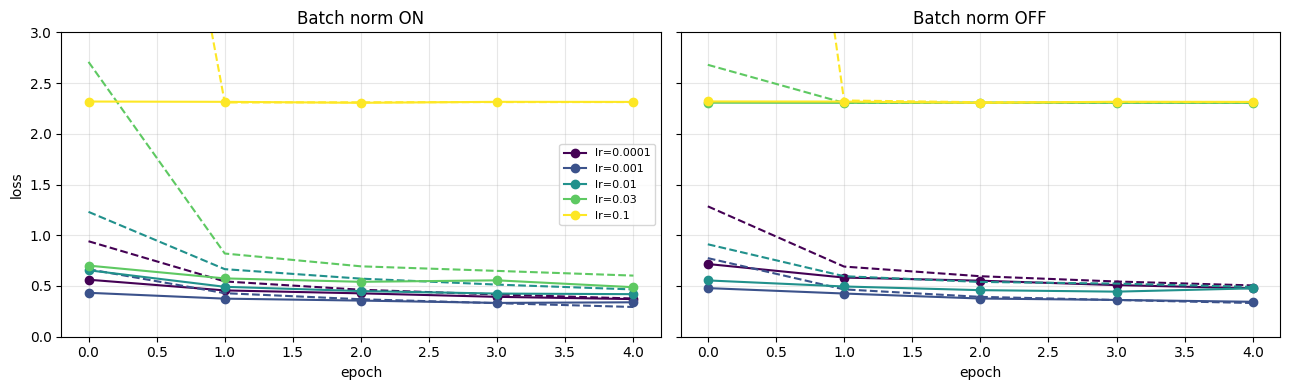

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
colors = plt.cm.viridis([i / (len(LRS) - 1) for i in range(len(LRS))])
for ax, bn in zip(axes, BN):
    for c, lr in zip(colors, LRS):
        h = runs[(bn, lr, 42)]
        ax.plot(h["epoch"], h["val_loss"],   "-",  color=c, marker="o", label=f"lr={lr:g}")
        ax.plot(h["epoch"], h["train_loss"], "--", color=c)
    ax.set(title=f"Batch norm {'ON' if bn else 'OFF'}", xlabel="epoch", ylim=(0, 3))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("loss"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 1.** Training (dashed) and validation (solid) loss per epoch for seed 42, one colour per learning rate; left is batch norm on, right is off. It shows which learning rates let the loss come down and which do not. Note that the BN-on, lr = 0.1 run for this seed is one of the runs that collapsed (about 11% accuracy), so that curve is not typical of that setting; Table 2 shows every seed.

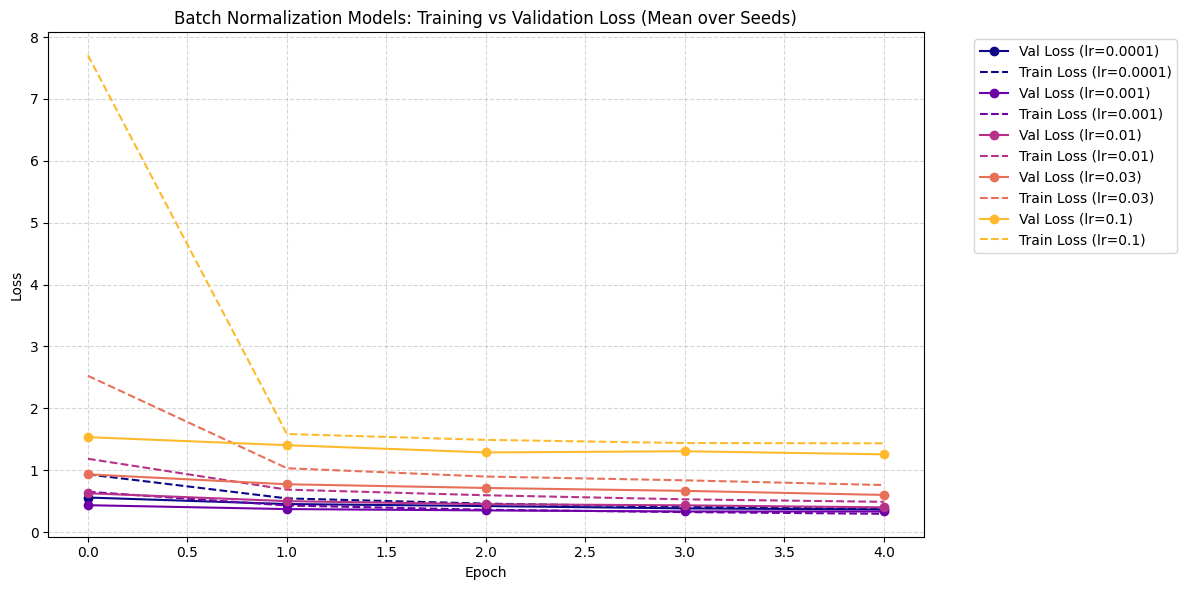

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Filter to only Batch Normalization ON (bn=True) and group by lr and epoch across seeds
bn_runs = []
for (bn, lr, seed), h in runs.items():
    if bn:
        for _, row in h.iterrows():
            bn_runs.append({
                'lr': lr,
                'epoch': row['epoch'],
                'train_loss': row['train_loss'],
                'val_loss': row['val_loss']
            })

df_bn = pd.DataFrame(bn_runs)
agg_bn = df_bn.groupby(['lr', 'epoch']).mean().reset_index()

plt.figure(figsize=(12, 6))
colors = plt.cm.plasma(np.linspace(0, 0.85, len(LRS)))

for c, lr in zip(colors, LRS):
    subset = agg_bn[agg_bn['lr'] == lr]
    # Solid line for validation loss, dashed for training loss
    plt.plot(subset['epoch'], subset['val_loss'], "-", color=c, marker="o", label=f"Val Loss (lr={lr:g})")
    plt.plot(subset['epoch'], subset['train_loss'], "--", color=c, label=f"Train Loss (lr={lr:g})")

plt.title("Batch Normalization Models: Training vs Validation Loss (Mean over Seeds)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Figure 2.** Training (dashed) and validation (solid) loss for the batch-norm models, averaged over the three seeds. Averaging hides the fact that at the highest learning rates some seeds trained and others did not, so I also look at each seed separately.

### Figure 3: final accuracy against learning rate

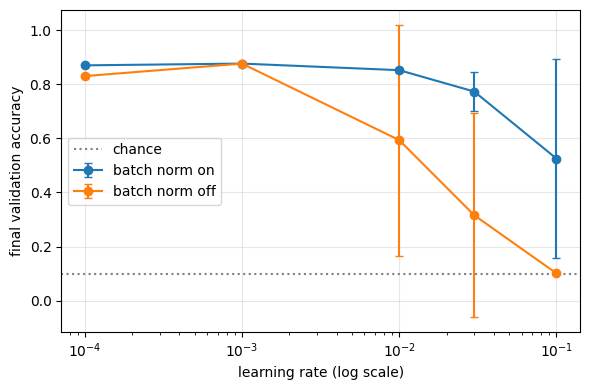

In [ ]:
rows = []
for (bn, lr, seed), h in runs.items():
    rows.append(dict(batchnorm=bn, lr=lr, seed=seed,
                     final_val_acc=h["val_acc"].iloc[-1], best_val_acc=h["val_acc"].max(),
                     final_val_loss=h["val_loss"].iloc[-1], final_train_loss=h["train_loss"].iloc[-1]))
df = pd.DataFrame(rows)
agg = df.groupby(["batchnorm", "lr"]).agg(
    val_acc_mean=("final_val_acc", "mean"), val_acc_std=("final_val_acc", "std"),
    val_loss_mean=("final_val_loss", "mean")).reset_index()

plt.figure(figsize=(6, 4))
for bn in BN:
    a = agg[agg.batchnorm == bn]
    plt.errorbar(a["lr"], a["val_acc_mean"], yerr=a["val_acc_std"], marker="o", capsize=3,
                 label=f"batch norm {'on' if bn else 'off'}")
plt.xscale("log"); plt.xlabel("learning rate (log scale)"); plt.ylabel("final validation accuracy")
plt.axhline(0.1, color="gray", ls=":", label="chance")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

**Figure 3.** Final validation accuracy (mean ± standard deviation over 3 seeds) against learning rate on a log axis; the dotted line is chance (10%). The two settings are indistinguishable at 1e-3, and BN is better at both smaller and larger rates.

### Table 1: mean and spread over seeds

In [ ]:
table = agg.pivot(index="lr", columns="batchnorm", values=["val_acc_mean", "val_acc_std"]).round(4)
table

val_acc_mean         val_acc_std        
batchnorm        False   True        False   True 
lr                                                
0.0001          0.8308  0.8704      0.0084  0.0030
0.0010          0.8769  0.8770      0.0045  0.0047
0.0100          0.5938  0.8526      0.4273  0.0080
0.0300          0.3158  0.7735      0.3784  0.0733
0.1000          0.1007  0.5256      0.0009  0.3672

**Table 1.** Mean and standard deviation of final validation accuracy for each learning rate (rows), with batch norm off (False) and on (True). A standard deviation near 0.4 means the three runs split between working and failing, so the next table lists each seed.

### Table 2: each seed on its own

In [ ]:
# Final validation accuracy per seed: values near 0.10 are runs that never learned
df.pivot_table(index="lr", columns=["batchnorm", "seed"], values="final_val_acc").round(3)

**Table 2.** Final validation accuracy for every individual run. Values near 0.10 are runs that stayed at chance, so you can read off how many of the three seeds trained at each setting.

---

## 5. Discussion

### What happened

| Learning rate | Val. accuracy, no BN | Val. accuracy, with BN | Verdict |
| :--- | :---: | :---: | :--- |
| $10^{-4}$ (small) | 83.1% ± 0.8 | **87.0% ± 0.3** | **BN wins:** higher accuracy after the same 5 epochs. |
| $10^{-3}$ (sweet spot) | 87.7% ± 0.5 | 87.7% ± 0.5 | **Tie:** identical peak, so BN adds nothing here. |
| $10^{-2}$ (aggressive) | 59.4% ± 42.7 | **85.3% ± 0.8** | **BN far more reliable:** all 3 seeds trained, versus 2 of 3 without BN. |
| $3\cdot10^{-2}$ (hostile) | 31.6% ± 37.8 | **77.4% ± 7.3** | **Both unreliable, BN better:** all 3 BN seeds trained (about 69–83%), only 1 of 3 without. |
| $10^{-1}$ (extreme) | 10.1% ± 0.1 | **52.6% ± 36.7** | **Both mostly fail:** 2 of 3 BN seeds reached about 74%, none without BN. |

Three things stand out. **The peaks are identical:** at the best learning rate, BN does not lift the ceiling. **BN shifts the safe range upward:** without it only 1e-3 and below trained reliably, with it 1e-2 did too, about one order of magnitude. **BN helps at small steps as well:** at 1e-4 it scored about 4 points higher after the same 5 epochs, which suggests faster learning, though I cannot tell whether the no-BN model would catch up with more epochs.

Failure is also seed-dependent, not just learning-rate-dependent. Without BN, seed 44 failed at 1e-2 yet trained at 3e-2 (Table 2). So a mean such as 59.4% ± 42.7 does not describe a model that is "sort of okay": it is a mix of runs that worked and runs that did not.

### Why do I think this happened?

The result fits the smoothing explanation from Section 1: if BN makes the loss landscape better behaved, a large step is less likely to throw the weights somewhere the loss explodes. The small-step result fits too, since normalised activations keep gradients at a useful scale. But my experiment shows the effect, not the cause. I did not measure gradient norms or curvature, so these remain hypotheses. Logging gradient norms for one BN-on and one BN-off run at lr = 1e-2 would be a natural next test.

### Did it match my expectations?

Mostly. I expected BN to stabilise high learning rates and it did. I did not expect the advantage at 1e-4, and I expected BN to hold up better at 1e-1 than it did.

### Real signal or noise?

Only the largest gaps are clearly bigger than the seed-to-seed spread: 1e-4 (4 points, against standard deviations under 1), and 1e-2 (all BN seeds trained, one non-BN seed did not). The tie at 1e-3 is well inside the noise. With only three seeds I make no claim of statistical significance.

### Limitations

A small CNN, a 10,000-image subset, only 5 epochs, one optimiser (Adam), one dataset and three seeds. Three seeds is thin exactly where the story is most interesting (3e-2 and 1e-1). I also did not measure training time, so I make no claim about BN's computational cost. Larger models, datasets or other optimisers could behave differently.

---

## 6. Takeaways

1. **Batch norm is a safety margin, not a speed-up.** At the best learning rate the two models were identical. Its value showed up when the learning rate was not well chosen.
2. **It widened the reliable learning-rate range by about a factor of ten** (1e-3 → 1e-2 here), but did not make training immune: at 3e-2 and above, runs still failed.
3. **Look at every seed, not just the mean.** Near the edge of stability, averages hide the fact that some runs fail completely.

So tuning the learning rate on a log scale remains essential, but leaving batch norm on makes that tuning more forgiving.

---

## References

- Ioffe, S. & Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift.* https://arxiv.org/abs/1502.03167
- Santurkar, S., Tsipras, D., Ilyas, A. & Madry, A. (2018). *How Does Batch Normalization Help Optimization?* https://arxiv.org/abs/1805.11604
- PyTorch documentation: [`BatchNorm2d`](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html), [`Adam`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html)
- Class notebook: `hyperparameters_lightning.ipynb`